# Confirmatory LOSO

Scope: Confirmatory LOSO in the WESAD protocol.

Input: Feature tables and `protocol_lock.json`.

Output and saved artifacts: `results/confirmatory_*.json` and `*_predictions.csv`; models; confusion matrices (under the configured output root; real `.parquet`, synthetic `.csv`).

Dependencies: Environment from `requirements.txt`, `src/` modules; setup dependencies only in notebook 00.

In [1]:
from pathlib import Path
import os, sys
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / 'configs/config.yaml').is_file() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Start Jupyter inside the project folder; no machine-specific path is required')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.config import load, setup, smoke_config
from src import workflow as w
SYNTHETIC = os.environ.get('WESAD_SYNTHETIC', '0') == '1'
c = load()
if SYNTHETIC: c = smoke_config(c)

# Reuse saved protocol instead of silently resetting extraction settings.
if not SYNTHETIC:
    import copy, json
    from src.config import fingerprint
    protocol_file = w.root(c) / 'protocol_lock.json'
    if protocol_file.is_file():
        from src.provenance import verify_lock
        saved_protocol = verify_lock(protocol_file)
        frozen = saved_protocol['config']
        if fingerprint(frozen) != saved_protocol['config_sha256']:
            raise ValueError('Saved protocol hash mismatch')
        c = copy.deepcopy(frozen)

setup(c)
print('Data mode:', 'SYNTHETIC EXECUTION ONLY' if SYNTHETIC else 'REAL WESAD')


Data mode: REAL WESAD


In [2]:
import copy
import json
from src.config import fingerprint, setup

# Riutilizza la configurazione salvata durante l'estrazione delle feature.
output_root = w.root(c).resolve()
lock_file = output_root / "protocol_lock.json"

if not lock_file.is_file():
    raise FileNotFoundError(
        f"Protocollo assente: {lock_file}. Esegui prima il notebook 02."
    )

with lock_file.open("r", encoding="utf-8") as f:
    lock = json.load(f)
from src.provenance import verify_lock
verify_lock(lock_file)

c = copy.deepcopy(lock["config"])

if fingerprint(c) != lock["config_sha256"]:
    raise ValueError(
        "La configurazione salvata non corrisponde all'hash del protocollo."
    )

if w.root(c).resolve() != output_root:
    raise ValueError(
        "La cartella di output del protocollo non corrisponde a quella selezionata."
    )

setup(c)

feature_dir = w.root(c) / "features"
fmt = c["output"]["feature_format"]

missing = [
    feature_dir / f"{site}_features.{fmt}"
    for site in ("chest", "wrist")
    if not (feature_dir / f"{site}_features.{fmt}").is_file()
]

if missing:
    raise FileNotFoundError(
        "Feature mancanti:\n" + "\n".join(str(path) for path in missing)
    )

tables = w.load_tables(c)
results = w.confirmatory_stage(tables, c)

for result in results:
    print(result["site"], result["model"], result["primary"])

print(
    "Ogni soggetto è usato come TEST una volta; "
    "negli altri fold LOSO partecipa al training."
)


early_fusion majority {'mean': 0.33333333333333326, 'ci95': [0.33333333333333326, 0.33333333333333326], 'unit': 'subject', 'n_subjects': 15, 'interpretation': 'conditional on fitted LOSO predictions; not full retraining uncertainty'}
early_fusion logistic_regression {'mean': 0.6820706928163067, 'ci95': [0.5917002775445758, 0.7672619575602031], 'unit': 'subject', 'n_subjects': 15, 'interpretation': 'conditional on fitted LOSO predictions; not full retraining uncertainty'}
early_fusion random_forest {'mean': 0.6743754150965194, 'ci95': [0.6034960410826639, 0.7453091291169208], 'unit': 'subject', 'n_subjects': 15, 'interpretation': 'conditional on fitted LOSO predictions; not full retraining uncertainty'}
chest majority {'mean': 0.33333333333333326, 'ci95': [0.33333333333333326, 0.33333333333333326], 'unit': 'subject', 'n_subjects': 15, 'interpretation': 'conditional on fitted LOSO predictions; not full retraining uncertainty'}
chest logistic_regression {'mean': 0.6566123795519295, 'ci95'

In [3]:
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    matthews_corrcoef,
)

# None = tutti i soggetti; esempio: [2, 5, 15]
SOGGETTI = None

results_dir = w.root(c) / "results"
prediction_files = sorted(
    results_dir.glob("confirmatory_*_predictions.csv")
)

if not prediction_files:
    raise FileNotFoundError(
        f"Nessuna predizione trovata in {results_dir.resolve()}."
    )

class_names = {1: "Baseline", 2: "Stress", 3: "Amusement"}
summary_rows = []
class_rows = []

for prediction_file in prediction_files:
    tag = prediction_file.name.removesuffix("_predictions.csv")

    with (results_dir / f"{tag}.json").open("r", encoding="utf-8") as f:
        metadata = json.load(f)

    classes = np.asarray(metadata["classes"], dtype=int)
    predictions = pd.read_csv(prediction_file)

    probabilities = predictions[
        [f"p_{label}" for label in classes]
    ].to_numpy(dtype=float)

    if not np.isfinite(probabilities).all():
        raise ValueError(f"Probabilità non valide in {prediction_file.name}")

    predictions["predicted_label"] = classes[
        probabilities.argmax(axis=1)
    ]

    for subject_id, subject in predictions.groupby("subject_id"):
        if SOGGETTI is not None and subject_id not in SOGGETTI:
            continue

        y_true = subject["label"].to_numpy()
        y_pred = subject["predicted_label"].to_numpy()

        precision, recall, f1, support = precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=classes,
            average=None,
            zero_division=0,
        )

        weighted_precision, weighted_recall, weighted_f1, _ = (
            precision_recall_fscore_support(
                y_true,
                y_pred,
                labels=classes,
                average="weighted",
                zero_division=0,
            )
        )

        common = {
            "site": metadata["site"],
            "model": metadata["model"],
            "subject_id": int(subject_id),
        }

        summary_rows.append({
            **common,
            "n_windows": len(subject),
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": precision.mean(),
            "recall_macro": recall.mean(),
            "f1_macro": f1.mean(),
            "precision_weighted": weighted_precision,
            "recall_weighted": weighted_recall,
            "f1_weighted": weighted_f1,
            "MCC": matthews_corrcoef(y_true, y_pred),
        })

        for index, label in enumerate(classes):
            class_rows.append({
                **common,
                "class": class_names.get(int(label), str(label)),
                "precision": precision[index],
                "recall": recall[index],
                "f1": f1[index],
                "support": int(support[index]),
            })

if not summary_rows:
    raise ValueError("Nessun soggetto corrisponde alla selezione.")

subject_metrics = pd.DataFrame(summary_rows).sort_values(
    ["site", "model", "subject_id"]
)
class_metrics = pd.DataFrame(class_rows).sort_values(
    ["site", "model", "subject_id", "class"]
)

metric_columns = [
    column for column in subject_metrics.columns
    if column not in ["site", "model", "subject_id", "n_windows"]
]

for (site, model), group in subject_metrics.groupby(["site", "model"]):
    display(Markdown(f"### {site} · {model} — metriche per soggetto"))
    display(
        group.drop(columns=["site", "model"])
        .style.format({column: "{:.3f}" for column in metric_columns})
        .hide(axis="index")
    )

    detail = class_metrics.loc[
        (class_metrics["site"] == site)
        & (class_metrics["model"] == model)
    ]

    display(Markdown("**Precision, recall e F1 per classe e soggetto**"))
    display(
        detail.drop(columns=["site", "model"])
        .style.format({
            "precision": "{:.3f}",
            "recall": "{:.3f}",
            "f1": "{:.3f}",
        })
        .hide(axis="index")
    )

display(Markdown(
    "### Media e deviazione standard tra soggetti\n"
    "Ogni soggetto ha lo stesso peso; la deviazione standard "
    "descrive la variabilità tra soggetti, non un intervallo di confidenza."
))

experiment_summary = subject_metrics.groupby(["site", "model"])[
    metric_columns
].agg(["mean", "std"])

display(experiment_summary.style.format("{:.3f}", na_rep="N/D"))

display(Markdown(
    "*Metriche calcolate sulle predizioni di test LOSO. "
    "Support indica il numero di finestre della classe reale. "
    "Le metriche con denominatore nullo sono impostate a 0.*"
))

### chest · logistic_regression — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.631,0.455,0.337,0.455,0.387,0.461,0.631,0.533,0.334
3,66,0.848,0.798,0.863,0.798,0.825,0.852,0.848,0.845,0.736
4,68,0.676,0.483,0.575,0.483,0.487,0.689,0.676,0.640,0.429
5,62,0.597,0.740,0.749,0.740,0.596,0.871,0.597,0.573,0.580
6,66,0.955,0.925,0.965,0.925,0.941,0.956,0.955,0.953,0.920
7,69,0.464,0.568,0.738,0.568,0.489,0.791,0.464,0.409,0.377
8,69,0.667,0.652,0.693,0.652,0.645,0.788,0.667,0.708,0.508
9,69,0.638,0.447,0.554,0.447,0.442,0.665,0.638,0.596,0.360
10,71,0.493,0.542,0.602,0.542,0.500,0.550,0.493,0.447,0.272
11,66,0.667,0.807,0.778,0.807,0.698,0.889,0.667,0.682,0.630


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,0.286,0.364,0.320,11
2,Baseline,0.725,1.000,0.841,37
2,Stress,0.000,0.000,0.000,17
3,Amusement,0.889,0.727,0.800,11
3,Baseline,0.833,0.946,0.886,37
3,Stress,0.867,0.722,0.788,18
4,Amusement,0.000,0.000,0.000,11
4,Baseline,0.725,1.000,0.841,37
4,Stress,1.000,0.450,0.621,20
5,Amusement,0.294,1.000,0.455,10


### chest · majority — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.569,0.333,0.190,0.333,0.242,0.324,0.569,0.413,0.000
3,66,0.561,0.333,0.187,0.333,0.239,0.314,0.561,0.403,0.000
4,68,0.544,0.333,0.181,0.333,0.235,0.296,0.544,0.383,0.000
5,62,0.516,0.333,0.172,0.333,0.227,0.266,0.516,0.351,0.000
6,66,0.576,0.333,0.192,0.333,0.244,0.331,0.576,0.421,0.000
7,69,0.551,0.333,0.184,0.333,0.237,0.303,0.551,0.391,0.000
8,69,0.536,0.333,0.179,0.333,0.233,0.288,0.536,0.374,0.000
9,69,0.551,0.333,0.184,0.333,0.237,0.303,0.551,0.391,0.000
10,71,0.521,0.333,0.174,0.333,0.228,0.272,0.521,0.357,0.000
11,66,0.576,0.333,0.192,0.333,0.244,0.331,0.576,0.421,0.000


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,0.000,0.000,0.000,11
2,Baseline,0.569,1.000,0.725,37
2,Stress,0.000,0.000,0.000,17
3,Amusement,0.000,0.000,0.000,11
3,Baseline,0.561,1.000,0.718,37
3,Stress,0.000,0.000,0.000,18
4,Amusement,0.000,0.000,0.000,11
4,Baseline,0.544,1.000,0.705,37
4,Stress,0.000,0.000,0.000,20
5,Amusement,0.000,0.000,0.000,10


### chest · random_forest — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.569,0.376,0.374,0.376,0.351,0.485,0.569,0.501,0.146
3,66,0.848,0.697,0.907,0.697,0.672,0.873,0.848,0.792,0.749
4,68,0.618,0.482,0.622,0.482,0.500,0.669,0.618,0.593,0.309
5,62,0.774,0.808,0.770,0.808,0.758,0.856,0.774,0.791,0.686
6,66,0.773,0.584,0.553,0.584,0.560,0.672,0.773,0.710,0.594
7,69,0.855,0.869,0.861,0.869,0.853,0.883,0.855,0.857,0.779
8,69,0.841,0.667,0.581,0.667,0.619,0.713,0.841,0.770,0.744
9,69,0.739,0.550,0.568,0.550,0.538,0.677,0.739,0.683,0.548
10,71,0.535,0.463,0.434,0.463,0.438,0.539,0.535,0.525,0.272
11,66,0.773,0.825,0.768,0.825,0.761,0.874,0.773,0.791,0.689


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,0.000,0.000,0.000,11
2,Baseline,0.623,0.892,0.733,37
2,Stress,0.500,0.235,0.320,17
3,Amusement,1.000,0.091,0.167,11
3,Baseline,0.822,1.000,0.902,37
3,Stress,0.900,1.000,0.947,18
4,Amusement,0.250,0.182,0.211,11
4,Baseline,0.615,0.865,0.719,37
4,Stress,1.000,0.400,0.571,20
5,Amusement,0.400,0.800,0.533,10


### early_fusion · logistic_regression — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.569,0.333,0.190,0.333,0.242,0.324,0.569,0.413,0.000
3,66,0.848,0.822,0.880,0.822,0.839,0.858,0.848,0.842,0.741
4,68,0.706,0.517,0.558,0.517,0.505,0.660,0.706,0.646,0.492
5,62,0.790,0.796,0.752,0.796,0.761,0.823,0.790,0.796,0.683
6,66,0.955,0.925,0.946,0.925,0.934,0.954,0.955,0.954,0.920
7,69,0.667,0.798,0.729,0.798,0.685,0.811,0.667,0.640,0.591
8,69,0.797,0.768,0.765,0.768,0.756,0.843,0.797,0.814,0.678
9,69,0.870,0.836,0.846,0.836,0.813,0.907,0.870,0.868,0.794
10,71,0.648,0.647,0.617,0.647,0.611,0.706,0.648,0.656,0.484
11,66,0.924,0.892,0.908,0.892,0.899,0.922,0.924,0.923,0.867


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,0.000,0.000,0.000,11
2,Baseline,0.569,1.000,0.725,37
2,Stress,0.000,0.000,0.000,17
3,Amusement,0.909,0.909,0.909,11
3,Baseline,0.814,0.946,0.875,37
3,Stress,0.917,0.611,0.733,18
4,Amusement,0.000,0.000,0.000,11
4,Baseline,0.673,1.000,0.804,37
4,Stress,1.000,0.550,0.710,20
5,Amusement,0.467,0.700,0.560,10


### early_fusion · majority — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.569,0.333,0.190,0.333,0.242,0.324,0.569,0.413,0.000
3,66,0.561,0.333,0.187,0.333,0.239,0.314,0.561,0.403,0.000
4,68,0.544,0.333,0.181,0.333,0.235,0.296,0.544,0.383,0.000
5,62,0.516,0.333,0.172,0.333,0.227,0.266,0.516,0.351,0.000
6,66,0.576,0.333,0.192,0.333,0.244,0.331,0.576,0.421,0.000
7,69,0.551,0.333,0.184,0.333,0.237,0.303,0.551,0.391,0.000
8,69,0.536,0.333,0.179,0.333,0.233,0.288,0.536,0.374,0.000
9,69,0.551,0.333,0.184,0.333,0.237,0.303,0.551,0.391,0.000
10,71,0.521,0.333,0.174,0.333,0.228,0.272,0.521,0.357,0.000
11,66,0.576,0.333,0.192,0.333,0.244,0.331,0.576,0.421,0.000


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,0.000,0.000,0.000,11
2,Baseline,0.569,1.000,0.725,37
2,Stress,0.000,0.000,0.000,17
3,Amusement,0.000,0.000,0.000,11
3,Baseline,0.561,1.000,0.718,37
3,Stress,0.000,0.000,0.000,18
4,Amusement,0.000,0.000,0.000,11
4,Baseline,0.544,1.000,0.705,37
4,Stress,0.000,0.000,0.000,20
5,Amusement,0.000,0.000,0.000,10


### early_fusion · random_forest — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.754,0.579,0.550,0.579,0.555,0.653,0.754,0.690,0.562
3,66,0.818,0.658,0.589,0.658,0.619,0.702,0.818,0.753,0.692
4,68,0.750,0.567,0.562,0.567,0.546,0.667,0.750,0.685,0.585
5,62,0.855,0.769,0.800,0.769,0.779,0.842,0.855,0.845,0.756
6,66,0.864,0.715,0.936,0.715,0.733,0.890,0.864,0.830,0.768
7,69,0.812,0.843,0.790,0.843,0.801,0.848,0.812,0.812,0.721
8,69,0.841,0.667,0.590,0.667,0.624,0.718,0.841,0.771,0.747
9,69,0.884,0.839,0.857,0.839,0.835,0.903,0.884,0.883,0.809
10,71,0.592,0.505,0.424,0.505,0.449,0.537,0.592,0.548,0.339
11,66,0.909,0.840,0.880,0.840,0.845,0.912,0.909,0.902,0.846


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,0.000,0.000,0.000,11
2,Baseline,0.720,0.973,0.828,37
2,Stress,0.929,0.765,0.839,17
3,Amusement,0.000,0.000,0.000,11
3,Baseline,0.766,0.973,0.857,37
3,Stress,1.000,1.000,1.000,18
4,Amusement,0.000,0.000,0.000,11
4,Baseline,0.685,1.000,0.813,37
4,Stress,1.000,0.700,0.824,20
5,Amusement,0.571,0.400,0.471,10


### wrist · logistic_regression — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.738,0.560,0.869,0.560,0.568,0.804,0.738,0.683,0.540
3,66,0.652,0.606,0.613,0.606,0.603,0.702,0.652,0.672,0.439
4,68,0.500,0.459,0.520,0.459,0.484,0.599,0.500,0.540,0.253
5,62,0.871,0.848,0.849,0.848,0.846,0.870,0.871,0.868,0.790
6,66,0.727,0.813,0.786,0.813,0.730,0.903,0.727,0.762,0.659
7,69,0.797,0.877,0.784,0.877,0.795,0.863,0.797,0.794,0.725
8,69,0.797,0.755,0.783,0.755,0.747,0.840,0.797,0.801,0.671
9,69,0.710,0.754,0.785,0.754,0.688,0.897,0.710,0.747,0.625
10,71,0.577,0.495,0.514,0.495,0.501,0.621,0.577,0.595,0.341
11,66,0.848,0.805,0.805,0.805,0.805,0.848,0.848,0.848,0.736


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,1.000,0.091,0.167,11
2,Baseline,0.698,1.000,0.822,37
2,Stress,0.909,0.588,0.714,17
3,Amusement,0.235,0.364,0.286,11
3,Baseline,0.781,0.676,0.725,37
3,Stress,0.824,0.778,0.800,18
4,Amusement,0.000,0.000,0.000,11
4,Baseline,0.560,0.378,0.452,37
4,Stress,1.000,1.000,1.000,20
5,Amusement,0.778,0.700,0.737,10


### wrist · majority — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.569,0.333,0.190,0.333,0.242,0.324,0.569,0.413,0.000
3,66,0.561,0.333,0.187,0.333,0.239,0.314,0.561,0.403,0.000
4,68,0.544,0.333,0.181,0.333,0.235,0.296,0.544,0.383,0.000
5,62,0.516,0.333,0.172,0.333,0.227,0.266,0.516,0.351,0.000
6,66,0.576,0.333,0.192,0.333,0.244,0.331,0.576,0.421,0.000
7,69,0.551,0.333,0.184,0.333,0.237,0.303,0.551,0.391,0.000
8,69,0.536,0.333,0.179,0.333,0.233,0.288,0.536,0.374,0.000
9,69,0.551,0.333,0.184,0.333,0.237,0.303,0.551,0.391,0.000
10,71,0.521,0.333,0.174,0.333,0.228,0.272,0.521,0.357,0.000
11,66,0.576,0.333,0.192,0.333,0.244,0.331,0.576,0.421,0.000


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,0.000,0.000,0.000,11
2,Baseline,0.569,1.000,0.725,37
2,Stress,0.000,0.000,0.000,17
3,Amusement,0.000,0.000,0.000,11
3,Baseline,0.561,1.000,0.718,37
3,Stress,0.000,0.000,0.000,18
4,Amusement,0.000,0.000,0.000,11
4,Baseline,0.544,1.000,0.705,37
4,Stress,0.000,0.000,0.000,20
5,Amusement,0.000,0.000,0.000,10


### wrist · random_forest — metriche per soggetto

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC
2,65,0.769,0.588,0.571,0.588,0.566,0.667,0.769,0.700,0.608
3,66,0.530,0.477,0.379,0.477,0.404,0.488,0.530,0.488,0.242
4,68,0.853,0.782,0.801,0.782,0.789,0.844,0.853,0.848,0.748
5,62,0.742,0.696,0.690,0.696,0.678,0.757,0.742,0.733,0.601
6,66,0.712,0.686,0.660,0.686,0.655,0.792,0.712,0.733,0.567
7,69,0.681,0.613,0.685,0.613,0.578,0.726,0.681,0.658,0.505
8,69,0.783,0.624,0.655,0.624,0.626,0.747,0.783,0.752,0.626
9,69,0.855,0.849,0.841,0.849,0.803,0.924,0.855,0.863,0.787
10,71,0.746,0.710,0.821,0.710,0.718,0.788,0.746,0.737,0.600
11,66,0.879,0.779,0.880,0.779,0.801,0.875,0.879,0.860,0.789


**Precision, recall e F1 per classe e soggetto**

subject_id,class,precision,recall,f1,support
2,Amusement,0.000,0.000,0.000,11
2,Baseline,0.712,1.000,0.831,37
2,Stress,1.000,0.765,0.867,17
3,Amusement,0.000,0.000,0.000,11
3,Baseline,0.621,0.486,0.545,37
3,Stress,0.515,0.944,0.667,18
4,Amusement,0.556,0.455,0.500,11
4,Baseline,0.846,0.892,0.868,37
4,Stress,1.000,1.000,1.000,20
5,Amusement,0.500,0.400,0.444,10


### Media e deviazione standard tra soggetti
Ogni soggetto ha lo stesso peso; la deviazione standard descrive la variabilità tra soggetti, non un intervallo di confidenza.

*Metriche calcolate sulle predizioni di test LOSO. Support indica il numero di finestre della classe reale. Le metriche con denominatore nullo sono impostate a 0.*

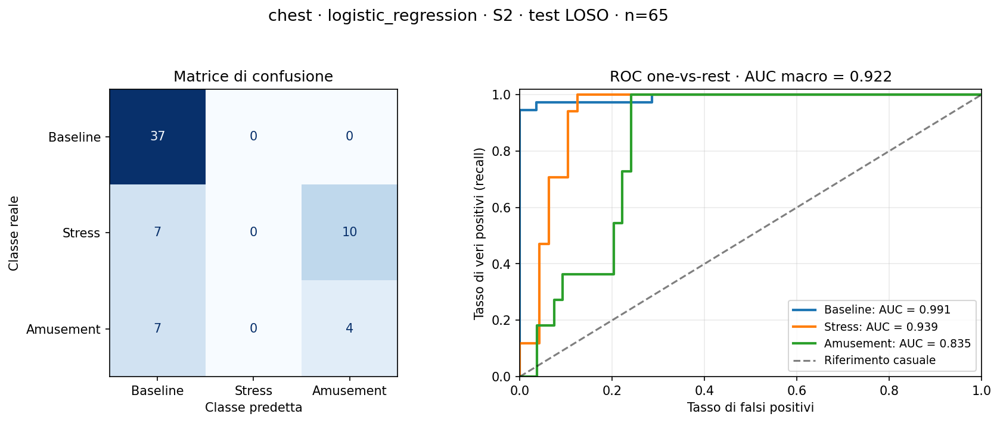

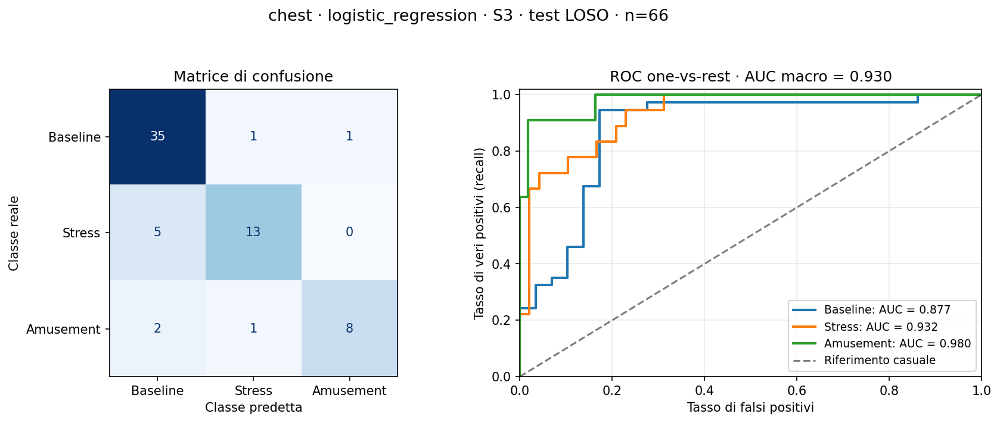

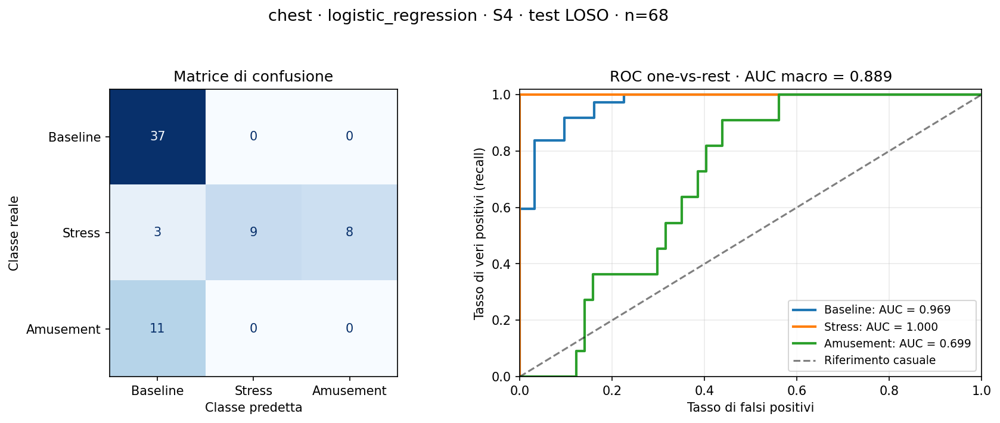

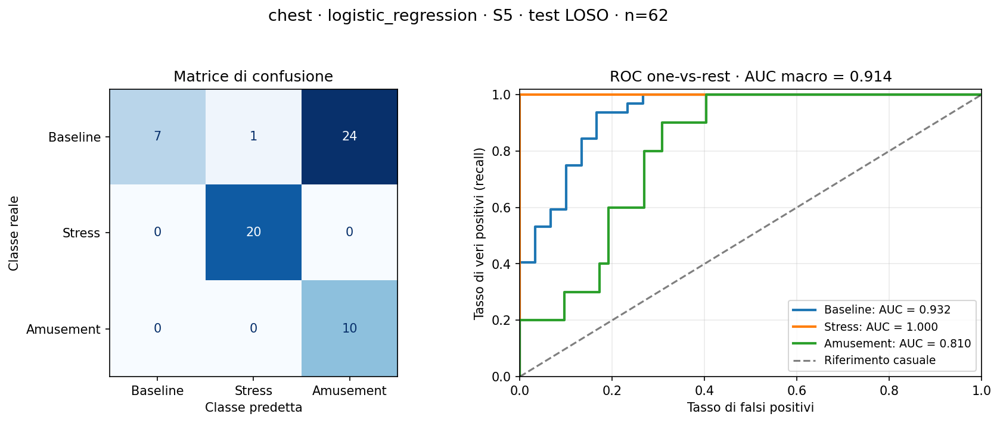

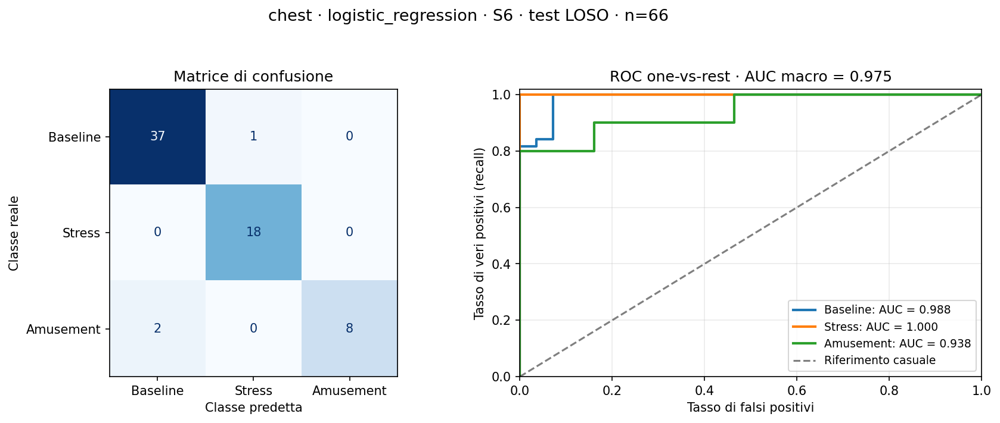

...

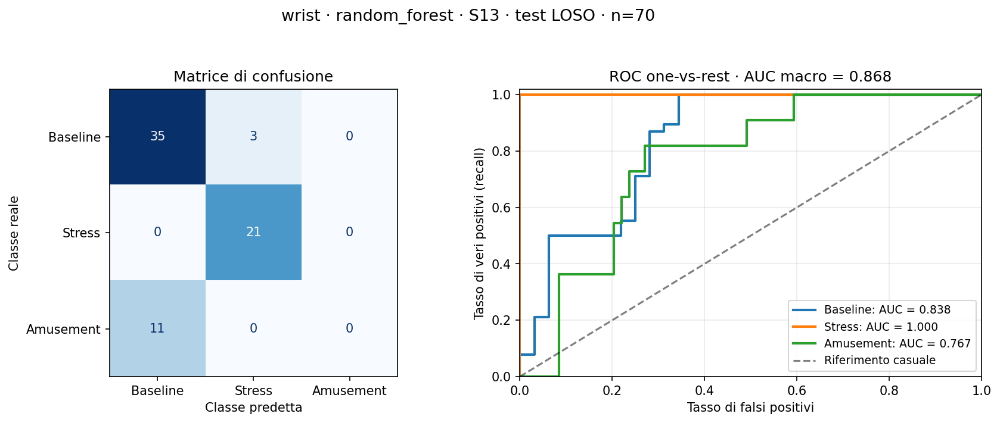

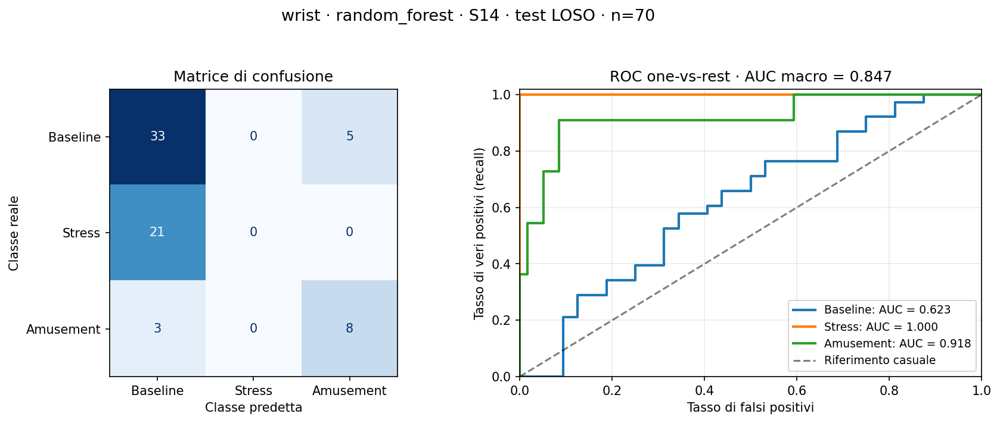

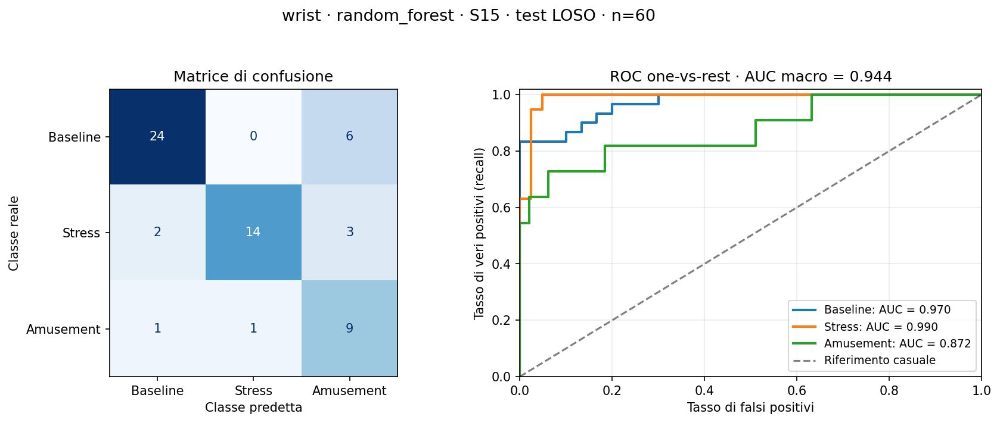

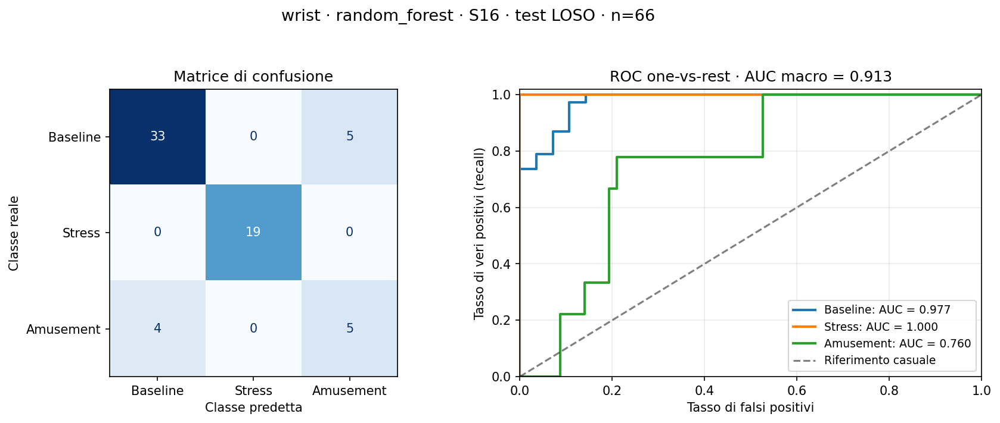

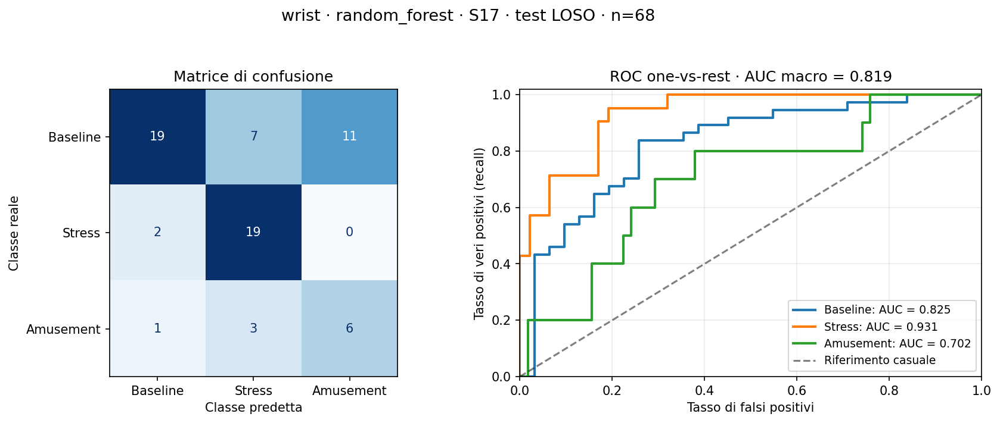

site,model,subject_id,class,roc_auc_ovr
chest,logistic_regression,2,Baseline,0.991
chest,logistic_regression,2,Stress,0.939
chest,logistic_regression,2,Amusement,0.835
chest,logistic_regression,2,Macro,0.922
chest,logistic_regression,3,Baseline,0.877
chest,logistic_regression,3,Stress,0.932
chest,logistic_regression,3,Amusement,0.980
chest,logistic_regression,3,Macro,0.930
chest,logistic_regression,4,Baseline,0.969
chest,logistic_regression,4,Stress,1.000


In [4]:
import json
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import Image, display
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
)

# None = tutti i soggetti; esempio: [2, 5, 15]
SOGGETTI = None

# True = proporzioni per classe reale; False = conteggi
NORMALIZZA = False

results_dir = w.root(c) / "results"
prediction_files = sorted(
    results_dir.glob("confirmatory_*_predictions.csv")
)

if not prediction_files:
    raise FileNotFoundError(
        f"Nessuna predizione trovata in {results_dir.resolve()}."
    )

class_names = {1: "Baseline", 2: "Stress", 3: "Amusement"}
auc_rows = []

for prediction_file in prediction_files:
    tag = prediction_file.name.removesuffix("_predictions.csv")

    with (results_dir / f"{tag}.json").open("r", encoding="utf-8") as f:
        metadata = json.load(f)

    classes = np.asarray(metadata["classes"], dtype=int)
    predictions = pd.read_csv(prediction_file)
    probability_columns = [f"p_{label}" for label in classes]

    for subject_id, subject in predictions.groupby("subject_id"):
        if SOGGETTI is not None and subject_id not in SOGGETTI:
            continue

        y_true = subject["label"].to_numpy()
        probabilities = subject[probability_columns].to_numpy(dtype=float)

        if not np.isfinite(probabilities).all():
            raise ValueError(
                f"Probabilità non valide: {tag}, soggetto {subject_id}"
            )

        y_pred = classes[probabilities.argmax(axis=1)]

        fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

        # Matrice di confusione.
        matrix = confusion_matrix(
            y_true,
            y_pred,
            labels=classes,
            normalize="true" if NORMALIZZA else None,
        )

        ConfusionMatrixDisplay(
            confusion_matrix=matrix,
            display_labels=[
                class_names.get(int(label), str(label))
                for label in classes
            ],
        ).plot(
            ax=axes[0],
            cmap="Blues",
            colorbar=False,
            values_format=".2f" if NORMALIZZA else "d",
            im_kw={"vmin": 0, "vmax": 1} if NORMALIZZA else None,
        )

        axes[0].set_title("Matrice di confusione")
        axes[0].set_xlabel("Classe predetta")
        axes[0].set_ylabel("Classe reale")

        # Curve ROC: ogni classe contro tutte le altre.
        subject_aucs = []

        for index, label in enumerate(classes):
            binary_true = (y_true == label).astype(int)
            name = class_names.get(int(label), str(label))

            if np.unique(binary_true).size < 2:
                class_auc = np.nan
                axes[1].plot(
                    [], [], label=f"{name}: AUC non definita"
                )
            else:
                fpr, tpr, _ = roc_curve(
                    binary_true, probabilities[:, index]
                )
                class_auc = auc(fpr, tpr)
                subject_aucs.append(class_auc)

                axes[1].plot(
                    fpr,
                    tpr,
                    linewidth=2,
                    label=f"{name}: AUC = {class_auc:.3f}",
                )

            auc_rows.append({
                "site": metadata["site"],
                "model": metadata["model"],
                "subject_id": int(subject_id),
                "class": name,
                "roc_auc_ovr": class_auc,
            })

        macro_auc = (
            float(np.mean(subject_aucs))
            if len(subject_aucs) == len(classes)
            else np.nan
        )

        auc_rows.append({
            "site": metadata["site"],
            "model": metadata["model"],
            "subject_id": int(subject_id),
            "class": "Macro",
            "roc_auc_ovr": macro_auc,
        })

        axes[1].plot(
            [0, 1],
            [0, 1],
            "k--",
            alpha=0.5,
            label="Riferimento casuale",
        )

        roc_title = (
            f"ROC one-vs-rest · AUC macro = {macro_auc:.3f}"
            if np.isfinite(macro_auc)
            else "ROC one-vs-rest · AUC macro non definita"
        )

        axes[1].set(
            xlabel="Tasso di falsi positivi",
            ylabel="Tasso di veri positivi (recall)",
            xlim=(0, 1),
            ylim=(0, 1.02),
            title=roc_title,
        )
        axes[1].legend(loc="lower right", fontsize=9)
        axes[1].grid(alpha=0.25)

        fig.suptitle(
            f"{metadata['site']} · {metadata['model']} · "
            f"S{int(subject_id)} · test LOSO · n={len(subject)}",
            fontsize=13,
        )
        fig.tight_layout(rect=(0, 0, 1, 0.94))

        # Visualizza come PNG anche con il backend Agg.
        with BytesIO() as buffer:
            fig.savefig(
                buffer,
                format="png",
                dpi=150,
                bbox_inches="tight",
            )
            png_data = buffer.getvalue()

        plt.close(fig)
        display(Image(data=png_data))

auc_table = pd.DataFrame(auc_rows)

if not auc_table.empty:
    display(
        auc_table.style
        .format({"roc_auc_ovr": "{:.3f}"}, na_rep="N/D")
        .hide(axis="index")
    )
else:
    print("Nessun soggetto corrisponde alla selezione SOGGETTI.")

## Interpretation of the primary LOSO results

### Evaluation scope

The primary task distinguishes **baseline, stress, and amusement**.

Evaluation includes **15 participants and 1,005 common valid windows**.
Chest, wrist, and early-fusion configurations are evaluated on the same
windows. Each participant is held out once for testing, with hyperparameter
tuning performed within the remaining training participants.

The primary endpoint is **balanced accuracy averaged equally across
participants**. Macro F1 and macro one-vs-rest ROC AUC are also averaged
across participants.

### Overall performance

| Configuration | Model | Balanced accuracy | Conditional 95% CI | Macro F1 | Macro ROC AUC |
|---|---|---:|---|---:|---:|
| Chest | Logistic regression | 65.66% | [58.26%, 73.43%] | 0.599 | 0.905 |
| Chest | Random forest | 63.05% | [55.06%, 70.77%] | 0.595 | 0.886 |
| Wrist | Logistic regression | 66.11% | [57.85%, 74.46%] | 0.635 | 0.868 |
| Wrist | Random forest | **68.29%** | [63.02%, 73.22%] | **0.656** | 0.879 |
| Early fusion | Logistic regression | 68.21% | [59.17%, 76.73%] | 0.636 | **0.908** |
| Early fusion | Random forest | 67.44% | [60.35%, 74.53%] | 0.642 | 0.904 |

The majority classifier always predicts baseline and obtains **33.33%
balanced accuracy**, **0.236 macro F1**, and **0.500 macro ROC AUC**.

All evaluated learning models descriptively outperform this reference.
The wrist random forest has the highest observed mean balanced accuracy,
but its advantage over early-fusion logistic regression is only about
**0.08 percentage points**. These means alone do not establish a definitive
winner.

The confidence intervals are obtained by resampling participants,
conditional on the fitted LOSO predictions. They do not include model
retraining within bootstrap samples. Shared training participants across
LOSO folds also limit independence.

### Does early fusion improve on wrist-only classification?

The saved paired comparisons evaluate early fusion minus wrist performance
within the same algorithm.

| Model | Mean BA difference | Conditional 95% CI |
|---|---:|---|
| Logistic regression | +2.10 percentage points | [−5.12, +8.37] |
| Random forest | −0.85 percentage points | [−7.45, +5.63] |

Both intervals include zero. These comparisons do not establish a
consistent advantage of early fusion over wrist-only classification.
They also do not demonstrate equivalence or wrist noninferiority.


### Class-specific errors

For the wrist random forest, the aggregated confusion matrix contains:

| True class | Correct predictions / windows | Pooled recall |
|---|---:|---:|
| Baseline | 438 / 550 | 79.6% |
| Stress | 250 / 295 | 84.7% |
| Amusement | 64 / 160 | 40.0% |

Of the 160 amusement windows, **81 are classified as baseline** and
15 as stress. Amusement is therefore a major source of error, particularly
through confusion with baseline.

These recalls are computed from pooled window counts. They differ from
equal-participant mean recalls because participants contribute different
numbers of windows. The primary balanced accuracy remains the mean of
participant-level balanced accuracies, not a metric calculated from the
summed confusion matrix.

### Variation across participants

Performance varies substantially between held-out participants.

For early-fusion logistic regression, balanced accuracy ranges from
**33.3% for S2** to **92.5% for S6**; S16 obtains **37.0%**.

For wrist random forest, it ranges from **47.7% for S3** to **84.9% for S9**.

This demonstrates heterogeneous generalization within the evaluated
sample. It does not identify the cause of the differences. Physiological
variation, signal quality, feature distributions, and model limitations
remain possible explanations.

Participants should not be excluded because their results are unfavorable.

### Precision, recall, F1 and ROC AUC

Precision measures the proportion of predictions assigned to a class that
are correct. Recall measures the proportion of that class that is
recognized. F1 balances precision and recall.

Macro averaging assigns equal weight to classes; weighted averaging gives
more weight to classes with more windows. The class imbalance therefore
makes accuracy and weighted metrics insufficient as standalone summaries.

In this three-class evaluation, macro recall equals balanced accuracy
because every participant has all three classes represented.

The relatively high ROC AUC values indicate useful ranking of class scores.
They do **not** imply approximately 90% classification accuracy or calibrated
probabilities. AUC evaluates discrimination across thresholds, whereas the
reported confusion matrices and F1 scores use the final argmax decisions.

Any alternative thresholds must be selected within training or calibration
data, without using the held-out participant.

### Conclusion

The evaluated pipelines show discrimination between laboratory conditions
in held-out WESAD participants. Wrist random forest achieves the highest
observed primary mean balanced accuracy, while early-fusion logistic
regression achieves the highest macro ROC AUC.

No definitive winner or systematic early-fusion benefit is established.
Amusement recognition and participant-level variability remain important
limitations. These results concern laboratory condition classification
and do not establish clinical validity or real-world stress detection.